# 01 · Análise exploratória (EDA) — Atria
**Pergunta guia:** onde o lojista ganha e onde perde? O que se repete, o que é exceção, e o que a Atria deveria mostrar logo cedo?
Os dados são **simulados** (4 lojas de moda, 7 plataformas, dez/2024 a nov/2026) e foram limpos pelo pipeline `prep.py` (log em `docs/log_preparacao.csv`).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings; warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"font.size":10})
D="../data/core/"; ped=pd.read_csv(D+"fato_pedido.csv",parse_dates=["data_pedido"]); conv=pd.read_csv(D+"fato_conversa.csv",parse_dates=["iniciada_em"])
post=pd.read_csv(D+"fato_post_instagram.csv",parse_dates=["publicado_em"]); plat=pd.read_csv(D+"dim_plataforma.csv").set_index("plataforma_id"); loja=pd.read_csv(D+"dim_loja.csv",parse_dates=["data_adocao_atria"])
ped["canal"]=ped.plataforma_id.map(plat.nome); ped["mes"]=ped.data_pedido.dt.to_period("M")

## 1. Visão geral e qualidade
Primeiro conferimos tamanho, tipos e nulos. Os nulos que existem são esperados (envio de pedido cancelado, resposta de conversa sem resposta).

In [2]:
print(ped.shape, conv.shape, post.shape)
print(ped.isna().mean().round(3)[lambda s:s>0])
ped[["valor_itens","taxa_plataforma","frete_custo","custo_produtos","lucro_liquido"]].describe().round(1)

(31421, 26) (47309, 19) (2044, 18)
data_envio           0.036
data_entrega         0.044
data_cancelamento    0.967
conversa_id          0.603
evento               0.841
dtype: float64


,valor_itens,taxa_plataforma,frete_custo,custo_produtos,lucro_liquido
count,31421.0,31421.0,31421.0,31421.0,31421.0
mean,205.0,18.3,14.8,82.8,81.8
std,139.2,16.8,6.8,60.4,79.8
min,14.8,0.0,0.0,0.0,-703.1
25%,99.9,6.7,10.9,38.4,35.5
50%,169.9,13.0,15.8,66.8,71.6
75%,269.8,23.7,19.3,112.9,114.1
max,1239.6,172.7,29.2,476.3,690.7


## 2. Distribuições
O ticket tem cauda longa à direita: poucos pedidos grandes puxam a média para cima, então a **mediana** é a medida honesta.

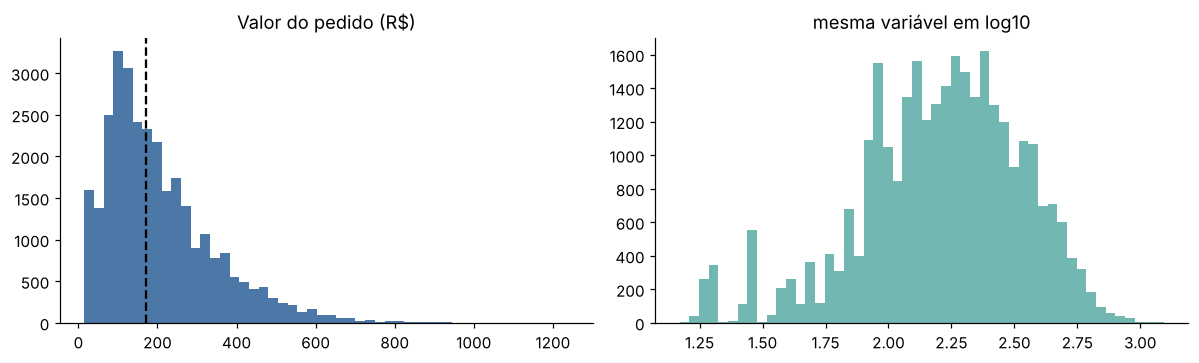

média 204.9 mediana 169.9 assimetria 1.33


In [3]:
v=ped[ped.status!="CANCELADO"].valor_itens
fig,ax=plt.subplots(1,2,figsize=(11,3.4)); ax[0].hist(v,bins=50,color="#4C78A8"); ax[0].axvline(v.median(),c="k",ls="--"); ax[0].set_title("Valor do pedido (R$)")
ax[1].hist(np.log10(v),bins=50,color="#72B7B2"); ax[1].set_title("mesma variável em log10"); plt.tight_layout(); plt.savefig("../out/fig/eda_ticket.png"); plt.show()
print("média",v.mean().round(1),"mediana",v.median().round(1),"assimetria",round(v.skew(),2))

## 3. Receita não é lucro: economia por canal
A mesma receita rende margens muito diferentes. Aqui aparece o primeiro achado de negócio.

,pedidos,receita,lucro,ticket_mediano,margem_%
canal,,,,,
Nuvemshop,15430,3241847.0,1540916.0,178.0,48.0
Shopee,5588,1124428.0,367879.0,168.0,33.0
Mercado Livre,5288,1056361.0,351462.0,170.0,33.0
TikTok Shop,2132,427493.0,184945.0,168.0,43.0
Shein,1947,376241.0,126161.0,164.0,34.0


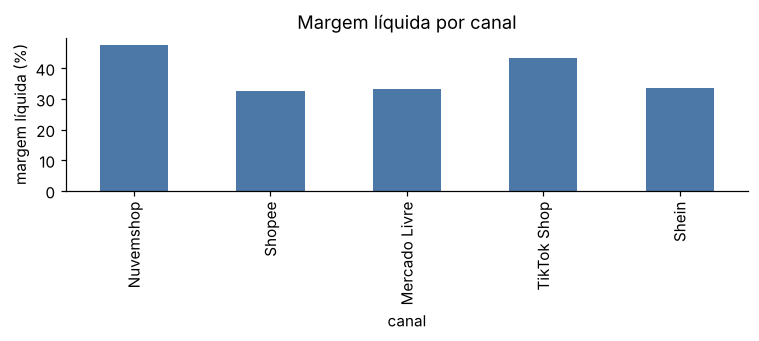

In [4]:
g=ped[ped.status!="CANCELADO"].groupby("canal").agg(pedidos=("pedido_id","size"),receita=("valor_itens","sum"),lucro=("lucro_liquido","sum"),ticket_mediano=("valor_itens","median"))
g["margem_%"]=(100*g.lucro/g.receita).round(1); g=g.sort_values("receita",ascending=False); display(g.round(0))
fig,ax=plt.subplots(figsize=(7,3.2)); (g["margem_%"]).plot.bar(ax=ax,color="#4C78A8"); ax.set_ylabel("margem líquida (%)"); ax.set_title("Margem líquida por canal"); plt.tight_layout(); plt.savefig("../out/fig/eda_margem.png"); plt.show()

**Interpretação.** A loja própria (Nuvemshop) e o TikTok Shop têm margem bem acima dos marketplaces clássicos, porque a comissão é menor. Nos marketplaces clássicos (Mercado Livre, Shopee, Shein) a margem líquida fica em torno de 33–34%, contra 43% no TikTok Shop e 48% na loja própria; o TikTok Shop ainda tem poucos pedidos. (Taxas e fretes são hipóteses da simulação.) Para o vendedor, isso muda a pergunta de “onde eu vendo mais?” para “onde eu **fico** com mais?”.

## 4. Tempo e sazonalidade

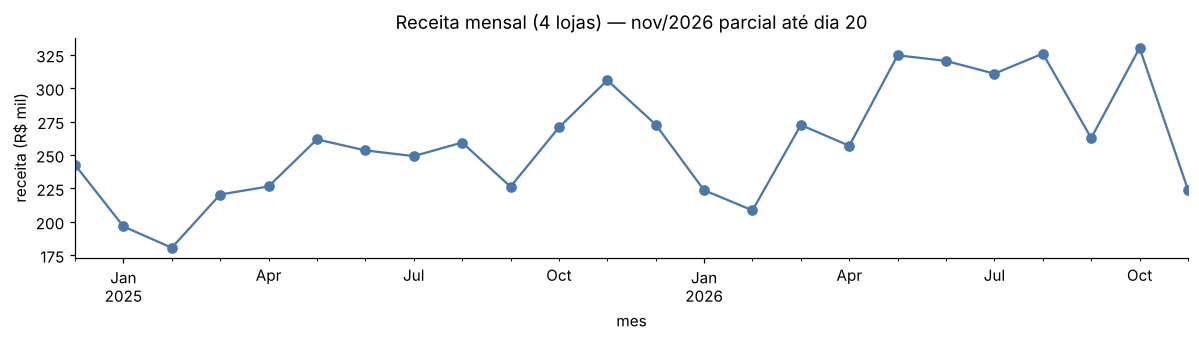

mes
2026-10    330.0
2026-08    326.0
2026-05    325.0
2026-06    320.0
2026-07    311.0
Freq: M, Name: valor_itens, dtype: float64


In [5]:
s=ped[ped.status!="CANCELADO"].groupby("mes").valor_itens.sum()/1000
fig,ax=plt.subplots(figsize=(11,3.2)); s.plot(ax=ax,marker="o",color="#4C78A8"); ax.set_ylabel("receita (R$ mil)"); ax.set_title("Receita mensal (4 lojas) — nov/2026 parcial até dia 20"); plt.tight_layout(); plt.savefig("../out/fig/eda_mensal.png"); plt.show()
print(s.round(0).sort_values(ascending=False).head(5))

**Interpretação.** Há dois movimentos misturados: uma **tendência de alta** (a receita mensal sobe de ~R$ 200 mil no início de 2025 para ~R$ 320 mil em meados de 2026) e **picos sazonais** moderados (nov/2025, com R$ 306 mil, e maio/2025 ficam acima dos meses vizinhos). Nov/2026 aparece baixo só porque o mês está incompleto: termina no dia 20 e a Black Friday (dia 27) ainda não ocorreu. Por isso comparar “antes vs depois” sem controle engana: parte do crescimento é calendário e tendência, não gestão. É o motivo de usarmos uma loja de controle no Efeito Atria.

## 5. Correlações
Procuramos relações entre variáveis de atendimento e resultado. Correlação não prova causa, mas indica onde investigar.

,log_resp,cliente_recorrente,valor_historico,msgs_cliente,enviou_midia,converteu_7d
log_resp,1.00,-0.00,0.00,-0.01,0.00,-0.10
cliente_recorrente,-0.00,1.00,0.55,0.01,-0.00,0.21
valor_historico,0.00,0.55,1.00,0.01,-0.01,0.14
msgs_cliente,-0.01,0.01,0.01,1.00,-0.01,0.01
enviou_midia,0.00,-0.00,-0.01,-0.01,1.00,0.00
converteu_7d,-0.10,0.21,0.14,0.01,0.00,1.00


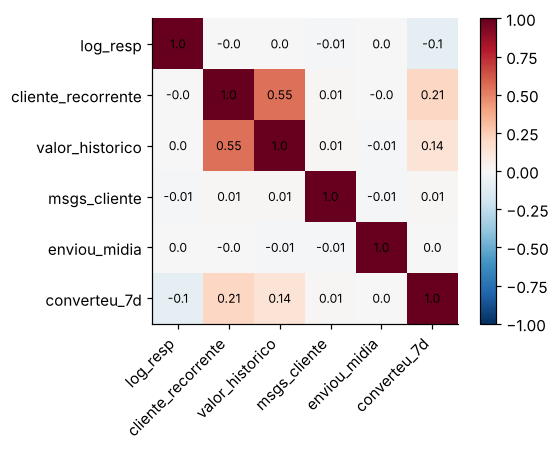

In [6]:
c=conv.dropna(subset=["tempo_primeira_resposta_min","converteu_7d"]).copy(); c["log_resp"]=np.log1p(c.tempo_primeira_resposta_min)
cols=["log_resp","cliente_recorrente","valor_historico","msgs_cliente","enviou_midia","converteu_7d"]; cm=c[cols].corr().round(2); display(cm)
import matplotlib; fig,ax=plt.subplots(figsize=(5.5,4.2)); im=ax.imshow(cm,cmap="RdBu_r",vmin=-1,vmax=1); ax.set_xticks(range(len(cols)),cols,rotation=45,ha="right"); ax.set_yticks(range(len(cols)),cols)
for i in range(len(cols)):
    for j in range(len(cols)): ax.text(j,i,cm.iloc[i,j],ha="center",va="center",fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.savefig("../out/fig/eda_corr.png"); plt.show()

**Interpretação.** O tempo de resposta (em log) tem correlação **negativa**, porém fraca (−0,10), com virar pedido: quem espera mais compra menos. Cliente recorrente (+0,21) e valor histórico (+0,14) têm relação positiva, e as duas são correlacionadas entre si (0,55), o que importa na regressão. Correlação isolada é pequena porque a **intenção** da conversa (não incluída aqui) pesa mais; os modelos dos notebooks seguintes combinam os fatores.

## 6. Agrupamentos: quando o atendimento demora, o que acontece?

,mean,size
faixa,,
até 15 min,0.374,1809
15–60 min,0.325,9558
1–4 h,0.294,12511
4–24 h,0.239,18388
mais de 24 h,0.196,2248


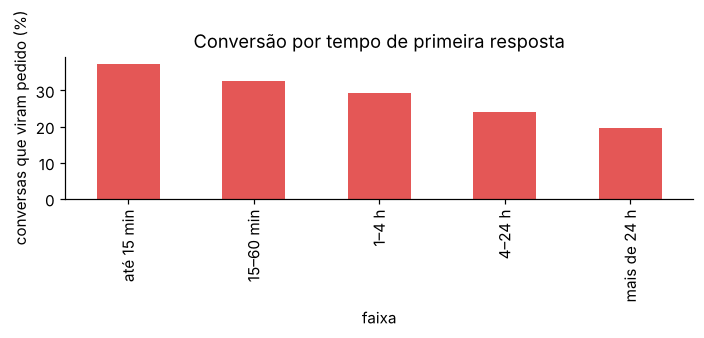

In [7]:
c["faixa"]=pd.cut(c.tempo_primeira_resposta_min,[0,15,60,240,1440,1e6],labels=["até 15 min","15–60 min","1–4 h","4–24 h","mais de 24 h"])
t=c.groupby("faixa",observed=True).converteu_7d.agg(["mean","size"]).round(3); display(t)
ax=t["mean"].mul(100).plot.bar(color="#E45756",figsize=(6.5,3)); ax.set_ylabel("conversas que viram pedido (%)"); ax.set_title("Conversão por tempo de primeira resposta"); plt.tight_layout(); plt.savefig("../out/fig/eda_conv_faixa.png"); plt.show()

**Interpretação.** A conversão cai de forma monotônica conforme a resposta demora (de 37% em até 15 min para 20% depois de 24 h). É um padrão acionável: a Atria deve destacar mensagens paradas há mais de 1 hora, que são as pendências de maior retorno.

## 7. Posts: o que gera conversa?

In [8]:
post["salv_comp"]=post.salvamentos+post.compartilhamentos
g=post.groupby("tipo").agg(posts=("post_id","size"),alcance_med=("alcance","median"),eng=("taxa_engajamento","median"),conversas=("conversas_48h_atribuidas","mean")).round(3); display(g)
print("corr(salvamentos+compart., conversas 48h) =",post[["salv_comp","conversas_48h_atribuidas"].copy()].corr().iloc[0,1].round(2),"| corr(curtidas, conversas) =",post[["curtidas","conversas_48h_atribuidas"]].corr().iloc[0,1].round(2))

,posts,alcance_med,eng,conversas
tipo,,,,
carrossel,685,1685.0,0.080,3.810
foto,670,1081.0,0.052,0.743
reels,689,4349.0,0.072,8.913


corr(salvamentos+compart., conversas 48h) = 0.97 | corr(curtidas, conversas) = 0.84


**Interpretação.** Reels e carrosséis geram muito mais conversas do que foto. Salvamentos+compartilhamentos têm correlação 0,97 com as conversas em 48 h; curtidas também têm correlação alta (0,84), porque posts de mais alcance recebem mais de tudo. Para separar o que é sinal de intenção do que é só alcance, usamos regressão múltipla no notebook 02.

## 8. Antes e depois, sem se enganar
Uma comparação simples “antes vs depois” da Atria mistura efeito da ferramenta com sazonalidade e tendência. Comparamos as lojas que adotaram com a loja de controle (diferença em diferenças).

grupo,controle,tratada
tri,,
2024Q4,263.0,200.0
2025Q1,250.0,251.0
2025Q2,210.0,250.0
2025Q3,234.0,230.0
2025Q4,268.0,180.0
2026Q1,260.0,140.0
2026Q2,264.0,120.0
2026Q3,275.0,121.0
2026Q4,264.0,105.0


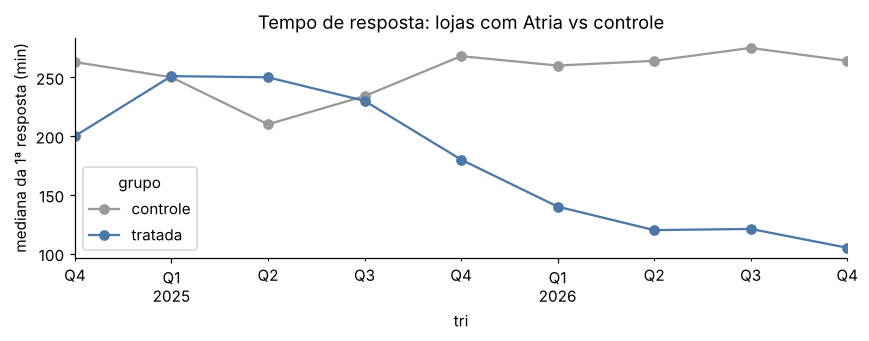

In [9]:
c2=conv.merge(loja[["loja_id","data_adocao_atria","grupo"]],on="loja_id"); c2["tri"]=c2.iniciada_em.dt.to_period("Q")
r=c2.groupby(["tri","grupo"]).tempo_primeira_resposta_min.median().unstack().round(0); display(r)
ax=r.plot(marker="o",figsize=(8,3.2),color=["#999","#4C78A8"]); ax.set_ylabel("mediana da 1ª resposta (min)"); ax.set_title("Tempo de resposta: lojas com Atria vs controle"); plt.tight_layout(); plt.savefig("../out/fig/eda_did.png"); plt.show()

**Interpretação.** De 2025T1 a 2025T3 as lojas que vão adotar ficam na faixa de ~230–250 min, perto do controle (~210–250). A partir de 2025T4 (primeiras adoções) a linha das lojas com Atria desce para ~105–140 min em 2026, enquanto o controle fica em ~260–275. Atenção: a linha “tratada” junta lojas com datas de adoção diferentes (cada uma entra no efeito em seu momento) e o controle também oscila com o acaso; o detalhamento por loja, com data de adoção, está no painel.

## Resumo dos achados
1. Margem varia muito por canal (~33–34% nos marketplaces clássicos, 43% no TikTok Shop e 48% na loja própria); receita sozinha engana.
2. Tendência de alta e sazonalidade moderada: comparações simples antes/depois são perigosas.
3. Resposta rápida está associada a mais conversão.
4. Reels e carrosséis geram muito mais conversas que fotos; salvamentos/compartilhamentos acompanham de perto as conversas.
5. Lojas com Atria respondem mais rápido que o controle, depois da adoção.